# Predictive Modeling for Ebro River Discharge

This notebook continues the analysis from `ebro-clustering.ipynb`, implementing predictive models for discharge prediction.

## Objectives

1. **Step 6.a**: Simple models `q = f(P)` for qmin, qav, qmax
2. **Step 6.b**: Enhanced models `q = f(P, soil_moisture)`
3. Compare model performance globally vs. by cluster
4. Evaluate different model types (Linear Regression, Random Forest, Gradient Boosting)

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import os
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore", message="Could not infer format")

## 🔬 Enhanced Imports for Comprehensive Analysis

Additional imports for:
- **SVM/SVR** models
- **Advanced metrics** (NSE, KGE for hydrology)
- **Feature importance** visualization
- **Residuals analysis** (statistical tests, QQ plots)

In [2]:
# Additional ML models
import sklearn
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

# Metrics and statistical analysis
from scipy import stats
from scipy.stats import shapiro, anderson, kstest
import scipy

# Feature importance visualization
from sklearn.inspection import permutation_importance

print("✅ Enhanced imports loaded")
print(f"   - Scikit-learn version: {sklearn.__version__}")
print(f"   - SciPy version: {scipy.__version__}")

✅ Enhanced imports loaded
   - Scikit-learn version: 1.7.2
   - SciPy version: 1.15.3


## 📊 Enhanced Performance Metrics

**Comprehensive metric suite for doctoral research quality evaluation:**

### Regression Metrics:
- **MSE/RMSE**: Standard squared error metrics
- **MAE**: Mean Absolute Error
- **R²**: Coefficient of determination

### Hydrological Metrics (Nash-Sutcliffe family):
- **NSE**: Nash-Sutcliffe Efficiency (-∞ to 1, optimal = 1)
  - NSE > 0.75: Excellent
  - NSE 0.65-0.75: Very good
  - NSE 0.50-0.65: Good
  - NSE < 0.50: Unsatisfactory

- **KGE**: Kling-Gupta Efficiency (-∞ to 1, optimal = 1)
  - Improved metric addressing limitations of NSE
  - Balances correlation, bias, and variability

### Bias Metrics:
- **Bias**: Mean bias (average error)
- **PBIAS**: Percent bias
  - PBIAS < ±10%: Excellent
  - PBIAS ±10-15%: Good
  - PBIAS ±15-25%: Satisfactory
  - PBIAS > ±25%: Unsatisfactory

### Additional:
- **MAPE**: Mean Absolute Percentage Error (%)

**References:**
- Nash & Sutcliffe (1970) - River flow forecasting
- Gupta et al. (2009) - Decomposition of NSE
- Moriasi et al. (2007) - Model evaluation guidelines

In [3]:
def calculate_nse(y_true, y_pred):
    """
    Calculate Nash-Sutcliffe Efficiency (NSE).

    NSE = 1 - [Σ(y_true - y_pred)²] / [Σ(y_true - mean(y_true))²]

    Range: -∞ to 1 (perfect fit)
    NSE = 1: Perfect match
    NSE = 0: Model as good as mean baseline
    NSE < 0: Model worse than mean baseline

    Reference: Nash & Sutcliffe (1970)
    """
    numerator = np.sum((y_true - y_pred) ** 2)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)

    if denominator == 0:
        return np.nan

    nse = 1 - (numerator / denominator)
    return nse

def calculate_kge(y_true, y_pred):
    """
    Calculate Kling-Gupta Efficiency (KGE).

    KGE = 1 - sqrt[(r-1)² + (α-1)² + (β-1)²]

    Where:
    - r: correlation coefficient
    - α: ratio of standard deviations (σ_pred / σ_true)
    - β: ratio of means (μ_pred / μ_true)

    Range: -∞ to 1 (perfect fit)

    Reference: Gupta et al. (2009)
    """
    # Correlation coefficient
    r = np.corrcoef(y_true, y_pred)[0, 1]

    # Alpha: ratio of standard deviations
    alpha = np.std(y_pred) / np.std(y_true)

    # Beta: ratio of means
    beta = np.mean(y_pred) / np.mean(y_true)

    # KGE
    kge = 1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2)

    return kge

def calculate_pbias(y_true, y_pred):
    """
    Calculate Percent Bias (PBIAS).

    PBIAS = [Σ(y_true - y_pred) / Σ(y_true)] × 100

    Optimal value: 0%
    Positive: Model underestimates
    Negative: Model overestimates

    Reference: Moriasi et al. (2007)
    """
    pbias = (np.sum(y_true - y_pred) / np.sum(y_true)) * 100
    return pbias

def calculate_mape(y_true, y_pred):
    """
    Calculate Mean Absolute Percentage Error (MAPE).

    MAPE = (100/n) × Σ|((y_true - y_pred) / y_true)|

    Returns percentage error (0-100+)
    """
    # Avoid division by zero
    mask = y_true != 0
    if not np.any(mask):
        return np.nan

    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    return mape

def evaluate_model_comprehensive(y_true, y_pred, model_name="Model"):
    """
    Calculate comprehensive model performance metrics.

    Returns dictionary with all metrics for comparison.
    """
    # Standard regression metrics
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    # Hydrological metrics
    nse = calculate_nse(y_true, y_pred)
    kge = calculate_kge(y_true, y_pred)

    # Bias metrics
    bias = np.mean(y_pred - y_true)
    pbias = calculate_pbias(y_true, y_pred)
    mape = calculate_mape(y_true, y_pred)

    results = {
        'Model': model_name,
        'RMSE': rmse,
        'MAE': mae,
        'R²': r2,
        'NSE': nse,
        'KGE': kge,
        'Bias': bias,
        'PBIAS_%': pbias,
        'MAPE_%': mape,
        'n_samples': len(y_true)
    }

    return results

def classify_performance(metrics):
    """
    Classify model performance based on hydrological standards.

    Returns classification string.
    """
    nse = metrics.get('NSE', -999)
    pbias = abs(metrics.get('PBIAS_%', 999))

    # NSE classification
    if nse > 0.75:
        nse_class = "Excellent"
    elif nse > 0.65:
        nse_class = "Very Good"
    elif nse > 0.50:
        nse_class = "Good"
    else:
        nse_class = "Unsatisfactory"

    # PBIAS classification
    if pbias < 10:
        pbias_class = "Excellent"
    elif pbias < 15:
        pbias_class = "Good"
    elif pbias < 25:
        pbias_class = "Satisfactory"
    else:
        pbias_class = "Unsatisfactory"

    return f"NSE: {nse_class}, PBIAS: {pbias_class}"

print("✅ Comprehensive metrics functions defined")
print("   Available metrics:")
print("   - Regression: RMSE, MAE, R²")
print("   - Hydrological: NSE, KGE")
print("   - Bias: Bias, PBIAS, MAPE")

✅ Comprehensive metrics functions defined
   Available metrics:
   - Regression: RMSE, MAE, R²
   - Hydrological: NSE, KGE
   - Bias: Bias, PBIAS, MAPE


## 🔍 Residuals Analysis Functions

**Comprehensive residuals diagnostics for model validation:**

### Statistical Tests:
- **Shapiro-Wilk**: Test for normality of residuals
- **Anderson-Darling**: Alternative normality test
- **Durbin-Watson**: Test for autocorrelation

### Visualizations:
- **Residuals vs Predicted**: Check for heteroscedasticity
- **QQ Plot**: Visual test for normality
- **Residuals Histogram**: Distribution of errors
- **Residuals Over Time**: Check for temporal patterns

**Purpose**: Verify model assumptions and identify systematic errors

In [4]:
def calculate_residuals_stats(y_true, y_pred, residuals=None):
    """
    Calculate comprehensive residuals statistics.

    Returns dictionary with statistical tests and descriptive stats.
    """
    if residuals is None:
        residuals = y_true - y_pred

    stats_dict = {
        'mean': np.mean(residuals),
        'std': np.std(residuals),
        'min': np.min(residuals),
        'max': np.max(residuals),
        'q25': np.percentile(residuals, 25),
        'median': np.median(residuals),
        'q75': np.percentile(residuals, 75),
        'skewness': stats.skew(residuals),
        'kurtosis': stats.kurtosis(residuals)
    }

    # Shapiro-Wilk test for normality (if sample size allows)
    if len(residuals) <= 5000:
        shapiro_stat, shapiro_p = shapiro(residuals)
        stats_dict['shapiro_stat'] = shapiro_stat
        stats_dict['shapiro_pvalue'] = shapiro_p
        stats_dict['is_normal_shapiro'] = shapiro_p > 0.05
    else:
        # For large samples, use Kolmogorov-Smirnov test
        ks_stat, ks_p = kstest(residuals, 'norm', args=(np.mean(residuals), np.std(residuals)))
        stats_dict['ks_stat'] = ks_stat
        stats_dict['ks_pvalue'] = ks_p
        stats_dict['is_normal_ks'] = ks_p > 0.05

    return stats_dict

def plot_residuals_analysis(y_true, y_pred, model_name="Model", save_path=None):
    """
    Create comprehensive residuals analysis plots.

    4-panel figure:
    1. Residuals vs Predicted
    2. QQ Plot
    3. Histogram of Residuals
    4. Residuals vs Index (time series)
    """
    residuals = y_true - y_pred

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'Residuals Analysis: {model_name}', fontsize=16, fontweight='bold')

    # 1. Residuals vs Predicted
    axes[0, 0].scatter(y_pred, residuals, alpha=0.5, s=10)
    axes[0, 0].axhline(y=0, color='r', linestyle='--', linewidth=2)
    axes[0, 0].set_xlabel('Predicted Values', fontsize=11)
    axes[0, 0].set_ylabel('Residuals', fontsize=11)
    axes[0, 0].set_title('Residuals vs Predicted Values', fontsize=12, fontweight='bold')
    axes[0, 0].grid(True, alpha=0.3)

    # Add smoothed trend line
    try:
        from scipy.interpolate import make_interp_spline
        if len(y_pred) > 100:
            # Sort for smooth line
            sorted_idx = np.argsort(y_pred)
            y_pred_sorted = y_pred[sorted_idx]
            residuals_sorted = residuals[sorted_idx]

            # Sample points for smoother (reduce if too many points)
            n_points = min(50, len(y_pred_sorted))
            indices = np.linspace(0, len(y_pred_sorted) - 1, n_points).astype(int)

            try:
                # Moving average for trend
                window = len(y_pred_sorted) // 20
                if window > 0:
                    trend = pd.Series(residuals_sorted).rolling(window=window, center=True).mean()
                    axes[0, 0].plot(y_pred_sorted, trend, 'g-', linewidth=2, alpha=0.7, label='Trend')
                    axes[0, 0].legend()
            except:
                pass
    except:
        pass

    # 2. QQ Plot
    stats.probplot(residuals, dist="norm", plot=axes[0, 1])
    axes[0, 1].set_title('Q-Q Plot (Normal Distribution)', fontsize=12, fontweight='bold')
    axes[0, 1].grid(True, alpha=0.3)

    # 3. Histogram of Residuals
    axes[1, 0].hist(residuals, bins=50, edgecolor='black', alpha=0.7, density=True)

    # Fit and plot normal distribution
    mu, sigma = np.mean(residuals), np.std(residuals)
    x = np.linspace(residuals.min(), residuals.max(), 100)
    axes[1, 0].plot(x, stats.norm.pdf(x, mu, sigma), 'r-', linewidth=2, label=f'Normal(μ={mu:.3f}, σ={sigma:.3f})')

    axes[1, 0].set_xlabel('Residuals', fontsize=11)
    axes[1, 0].set_ylabel('Density', fontsize=11)
    axes[1, 0].set_title('Distribution of Residuals', fontsize=12, fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    # 4. Residuals vs Index (temporal pattern)
    axes[1, 1].plot(residuals, alpha=0.6, linewidth=0.8)
    axes[1, 1].axhline(y=0, color='r', linestyle='--', linewidth=2)
    axes[1, 1].set_xlabel('Observation Index', fontsize=11)
    axes[1, 1].set_ylabel('Residuals', fontsize=11)
    axes[1, 1].set_title('Residuals Over Time (Sequential)', fontsize=12, fontweight='bold')
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"   Saved: {save_path}")

    plt.show()

    # Print statistical summary
    res_stats = calculate_residuals_stats(y_true, y_pred, residuals)

    print(f"\n{'='*80}")
    print(f"RESIDUALS STATISTICS: {model_name}")
    print(f"{'='*80}")
    print(f"  Mean: {res_stats['mean']:.6f} (should be ≈ 0)")
    print(f"  Std Dev: {res_stats['std']:.4f}")
    print(f"  Min: {res_stats['min']:.4f}")
    print(f"  Q25: {res_stats['q25']:.4f}")
    print(f"  Median: {res_stats['median']:.4f}")
    print(f"  Q75: {res_stats['q75']:.4f}")
    print(f"  Max: {res_stats['max']:.4f}")
    print(f"  Skewness: {res_stats['skewness']:.4f} (should be ≈ 0 for normal)")
    print(f"  Kurtosis: {res_stats['kurtosis']:.4f} (should be ≈ 0 for normal)")

    if 'shapiro_pvalue' in res_stats:
        print(f"\n  Shapiro-Wilk Test (Normality):")
        print(f"    Statistic: {res_stats['shapiro_stat']:.4f}")
        print(f"    P-value: {res_stats['shapiro_pvalue']:.4f}")
        print(f"    Normal? {res_stats['is_normal_shapiro']} (α=0.05)")
    elif 'ks_pvalue' in res_stats:
        print(f"\n  Kolmogorov-Smirnov Test (Normality):")
        print(f"    Statistic: {res_stats['ks_stat']:.4f}")
        print(f"    P-value: {res_stats['ks_pvalue']:.4f}")
        print(f"    Normal? {res_stats['is_normal_ks']} (α=0.05)")

    print(f"{'='*80}\n")

    return res_stats

print("✅ Residuals analysis functions defined")

✅ Residuals analysis functions defined


## 🎯 Feature Importance Analysis

**Understanding which variables drive predictions:**

### Methods:
- **Tree-based importance**: Built-in feature importance from Random Forest/Gradient Boosting
  - Based on reduction in impurity (Gini/entropy)
  - Fast but can be biased toward high-cardinality features

- **Permutation importance**: Model-agnostic approach
  - Measures decrease in performance when feature is shuffled
  - More reliable but computationally expensive

**Purpose**: Identify most influential predictors for discharge prediction

In [5]:
def plot_feature_importance(model, feature_names, model_name="Model", top_n=None, save_path=None):
    """
    Plot feature importance for tree-based models.

    Works with: RandomForest, GradientBoosting, DecisionTree
    """
    # Check if model has feature_importances_
    if not hasattr(model, 'feature_importances_'):
        print(f"⚠️  {model_name} does not support built-in feature importance")
        return None

    importances = model.feature_importances_
    indices = np.argsort(importances)[::-1]

    # Limit to top_n if specified
    if top_n and top_n < len(indices):
        indices = indices[:top_n]

    # Create plot
    plt.figure(figsize=(10, max(6, len(indices) * 0.3)))
    plt.title(f'Feature Importance: {model_name}', fontsize=14, fontweight='bold')

    plt.barh(range(len(indices)), importances[indices], align='center')
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel('Importance Score', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.gca().invert_yaxis()
    plt.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"   Saved: {save_path}")

    plt.show()

    # Print importance values
    print(f"\n{'='*60}")
    print(f"FEATURE IMPORTANCE: {model_name}")
    print(f"{'='*60}")
    for i, idx in enumerate(indices, 1):
        print(f"  {i:2d}. {feature_names[idx]:20s}: {importances[idx]:.6f}")
    print(f"{'='*60}\n")

    # Return as DataFrame
    importance_df = pd.DataFrame({
        'Feature': [feature_names[i] for i in indices],
        'Importance': importances[indices]
    })

    return importance_df

def plot_permutation_importance(model, X, y, feature_names, model_name="Model", n_repeats=10, top_n=None, save_path=None):
    """
    Calculate and plot permutation importance (model-agnostic).

    More robust but computationally expensive.
    """
    print(f"Calculating permutation importance for {model_name}...")
    print(f"  (n_repeats={n_repeats}, this may take a minute...)")

    # Calculate permutation importance
    perm_importance = permutation_importance(
        model, X, y,
        n_repeats=n_repeats,
        random_state=42,
        n_jobs=-1
    )

    # Get sorted indices
    indices = np.argsort(perm_importance.importances_mean)[::-1]

    # Limit to top_n
    if top_n and top_n < len(indices):
        indices = indices[:top_n]

    # Create plot
    plt.figure(figsize=(10, max(6, len(indices) * 0.3)))
    plt.title(f'Permutation Importance: {model_name}', fontsize=14, fontweight='bold')

    # Plot with error bars
    plt.barh(range(len(indices)),
             perm_importance.importances_mean[indices],
             xerr=perm_importance.importances_std[indices],
             align='center')

    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel('Importance (decrease in score)', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.gca().invert_yaxis()
    plt.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"   Saved: {save_path}")

    plt.show()

    # Print results
    print(f"\n{'='*70}")
    print(f"PERMUTATION IMPORTANCE: {model_name}")
    print(f"{'='*70}")
    for i, idx in enumerate(indices, 1):
        mean_imp = perm_importance.importances_mean[idx]
        std_imp = perm_importance.importances_std[idx]
        print(f"  {i:2d}. {feature_names[idx]:20s}: {mean_imp:.6f} ± {std_imp:.6f}")
    print(f"{'='*70}\n")

    # Return as DataFrame
    importance_df = pd.DataFrame({
        'Feature': [feature_names[i] for i in indices],
        'Importance_Mean': perm_importance.importances_mean[indices],
        'Importance_Std': perm_importance.importances_std[indices]
    })

    return importance_df

print("✅ Feature importance functions defined")

✅ Feature importance functions defined


## Load Cleaned Data

Loading the merged data created in previous notebooks.

In [6]:
base_path = "../../data/clean/merged_data/"

# Reconstruct the dictionary
join_dict = {}

for filename in os.listdir(base_path):
    if filename.endswith("-with-outliers.json"):
        basin_name = os.path.splitext(filename)[0]
        df = pd.read_json(os.path.join(base_path, filename), orient="records")
        join_dict[basin_name] = df

print(f"Loaded data for {len(join_dict)} basins:")
print(list(join_dict.keys()))

Loaded data for 18 basins:
['Tiron-with-outliers', 'Oroncillo-with-outliers', 'Rudron-with-outliers', 'Larraun-with-outliers', 'Zatoya-with-outliers', 'Flamisell-with-outliers', 'Vallfarrera-with-outliers', 'Yanguas-with-outliers', 'Garona-with-outliers', 'Urrobi-with-outliers', 'Anduña-with-outliers', 'Bailin-with-outliers', 'Nela-with-outliers', 'Deza-with-outliers', 'Ubagua-with-outliers', 'Isuela-with-outliers', 'Subialde-with-outliers', 'Sangüesa-with-outliers']


## 📊 Datos SMAP Integrados

**Actualización**: El dataset ahora incluye datos de SMAP (Soil Moisture Active Passive) de la NASA.

### Nuevas Variables (10 columnas):

**Humedad del Suelo - Zona Radicular**:
- `sm_rootzone_av` - Promedio
- `sm_rootzone_dif` - Diferencia
- `sm_rootzone_max` - Máximo
- `sm_rootzone_min` - Mínimo

**Humedad del Suelo - Superficie**:
- `sm_surface_av` - Promedio
- `sm_surface_dif` - Diferencia
- `sm_surface_max` - Máximo
- `sm_surface_min` - Mínimo

**Caudales SMAP**:
- `q0_r` - Caudal zona radicular
- `q0_s` - Caudal superficial

Estas variables pueden mejorar significativamente los análisis y modelos predictivos.

In [7]:
# Verificar presencia de columnas SMAP
sample_basin = list(join_dict.keys())[0]
smap_cols = [col for col in join_dict[sample_basin].columns if 'sm_' in col or 'q0_' in col]

print(f"✅ Dataset cargado con {len(join_dict)} cuencas")
print(f"📊 Columnas totales: {len(join_dict[sample_basin].columns)}")
print(f"🎯 Columnas SMAP encontradas ({len(smap_cols)}): {smap_cols}")

if len(smap_cols) == 0:
    print("\n⚠️  WARNING: No se encontraron columnas SMAP.")
    print("   Asegúrate de ejecutar el notebook 0-ebro-data-cleaning.ipynb primero.")

✅ Dataset cargado con 18 cuencas
📊 Columnas totales: 69
🎯 Columnas SMAP encontradas (10): ['q0_r', 'q0_s', 'sm_rootzone_av', 'sm_rootzone_dif', 'sm_rootzone_max', 'sm_rootzone_min', 'sm_surface_av', 'sm_surface_dif', 'sm_surface_max', 'sm_surface_min']


In [8]:
# Check sample data
sample_basin = list(join_dict.keys())[0]
print(f"\nSample data from {sample_basin}:")
join_dict[sample_basin].head()


Sample data from Tiron-with-outliers:


,Area_nm,CN_DT,CN_ponderado,DT_ks,DT_n,DT_swcfc,DT_swcpwp,DT_thau,DT_thetar,DT_thetas,...,wvmax,x_max_25830,x_min_25830,y_max_25830,y_min_25830,yav,ymax,ymin,z_max,z_min
0,Tiron,5.48766,85.0768,3.445952,0.045862,0.01721,0.040033,21.722671,0.007533,0.008974,...,7.27,492605.0,476673.0,4692929.0,4675527,0.06,0.06,0.06,2129.458008,805.098022
1,Tiron,5.48766,85.0768,3.445952,0.045862,0.01721,0.040033,21.722671,0.007533,0.008974,...,12.54,492605.0,476673.0,4692929.0,4675527,0.06,0.07,0.06,2129.458008,805.098022
2,Tiron,5.48766,85.0768,3.445952,0.045862,0.01721,0.040033,21.722671,0.007533,0.008974,...,9.16,492605.0,476673.0,4692929.0,4675527,0.06,0.07,0.06,2129.458008,805.098022
3,Tiron,5.48766,85.0768,3.445952,0.045862,0.01721,0.040033,21.722671,0.007533,0.008974,...,9.85,492605.0,476673.0,4692929.0,4675527,0.06,0.06,0.06,2129.458008,805.098022
4,Tiron,5.48766,85.0768,3.445952,0.045862,0.01721,0.040033,21.722671,0.007533,0.008974,...,6.15,492605.0,476673.0,4692929.0,4675527,0.06,0.07,0.06,2129.458008,805.098022


## Load Cluster Assignments

Load the cluster assignments from the clustering analysis.

In [9]:
# Manually define cluster assignments from ebro-clustering.ipynb
# These were determined using K-Means clustering (k=3)

cluster_assignments = {
    'Cluster_0': ['Deza', 'Flamisell', 'Zidacos', 'Subialde', 'Zatoya', 'Vallfarrera', 
                  'Anduña', 'Isuela', 'Urrobi', 'Oroncillo', 'Sangüesa', 'Tiron', 
                  'Rudron', 'Garona', 'Ubagua'],
    'Cluster_1': ['Bailin'],
    'Cluster_2': ['Larraun', 'Trueba', 'Nela']
}

# Create a reverse mapping: basin -> cluster
basin_to_cluster = {}
for cluster_name, basins in cluster_assignments.items():
    for basin in basins:
        basin_to_cluster[basin] = cluster_name

print("Cluster assignments:")
for cluster, basins in cluster_assignments.items():
    print(f"  {cluster}: {len(basins)} basins")

Cluster assignments:
  Cluster_0: 15 basins
  Cluster_1: 1 basins
  Cluster_2: 3 basins


## Data Preparation

Prepare datasets for modeling:
- Create combined dataset for global models
- Create cluster-specific datasets
- Handle missing values
- Create train/test splits

In [10]:
# Combine all basins into a single global dataset
all_basins_data = []

for basin_name, df in join_dict.items():
    df_copy = df.copy()
    df_copy['Basin'] = basin_name
    df_copy['Cluster'] = basin_to_cluster.get(basin_name, 'Unknown')
    all_basins_data.append(df_copy)

global_df = pd.concat(all_basins_data, ignore_index=True)

print(f"Global dataset shape: {global_df.shape}")
print(f"\nMissing values (% of total):")
print((global_df.isnull().sum() / len(global_df) * 100).round(2))

Global dataset shape: (32796, 71)

Missing values (% of total):
Area_nm         0.0
CN_DT           0.0
CN_ponderado    0.0
DT_ks           0.0
DT_n            0.0
               ... 
ymin            0.0
z_max           0.0
z_min           0.0
Basin           0.0
Cluster         0.0
Length: 71, dtype: float64


In [11]:
# Create cluster-specific datasets
cluster_data = {}

for cluster_name, basins in cluster_assignments.items():
    cluster_dfs = [join_dict[basin].copy() for basin in basins if basin in join_dict]
    if cluster_dfs:
        cluster_df = pd.concat(cluster_dfs, ignore_index=True)
        cluster_data[cluster_name] = cluster_df
        print(f"{cluster_name}: {len(cluster_df)} observations from {len(basins)} basins")

In [13]:
# Handle missing values - drop rows with NaN in key columns
key_columns = ['P', 
               # 'soil_moisture', 
               'qmin', 
               'qav', 
               'qmax']

# For global dataset
global_df_clean = global_df.dropna(subset=key_columns)
print(f"Global dataset after removing NaN: {global_df_clean.shape} (removed {len(global_df) - len(global_df_clean)} rows)")

# For cluster datasets
for cluster_name in cluster_data.keys():
    original_len = len(cluster_data[cluster_name])
    cluster_data[cluster_name] = cluster_data[cluster_name].dropna(subset=key_columns)
    new_len = len(cluster_data[cluster_name])
    print(f"{cluster_name} after removing NaN: {new_len} (removed {original_len - new_len} rows)")

Global dataset after removing NaN: (32748, 71) (removed 48 rows)


## Model Evaluation Functions

Define helper functions for model training and evaluation.

In [14]:
def evaluate_model(y_true, y_pred, model_name="Model"):
    """
    Calculate and display model performance metrics.
    """
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    results = {
        'Model': model_name,
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R²': r2
    }
    
    return results

def plot_predictions(y_true, y_pred, title="Predictions vs Actual"):
    """
    Plot predicted vs actual values.
    """
    plt.figure(figsize=(8, 6))
    plt.scatter(y_true, y_pred, alpha=0.5)
    
    # Plot perfect prediction line
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect prediction')
    
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def train_and_evaluate(X_train, X_test, y_train, y_test, model, model_name):
    """
    Train a model and evaluate its performance.
    """
    # Train model
    model.fit(X_train, y_train)
    
    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    # Evaluate
    train_results = evaluate_model(y_train, y_train_pred, f"{model_name} (Train)")
    test_results = evaluate_model(y_test, y_test_pred, f"{model_name} (Test)")
    
    return model, train_results, test_results, y_test_pred

# Step 6.a: Simple Models q = f(P)

Build simple models predicting discharge based only on precipitation (P).

## 6.a.1: Global Model - Predict qav from P

In [15]:
# Prepare data for qav ~ P
X = global_df_clean[['P']].values
y = global_df_clean['qav'].values

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

# Test multiple models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results_6a_global = []
predictions_6a = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    trained_model, train_res, test_res, y_pred = train_and_evaluate(
        X_train, X_test, y_train, y_test, model, model_name
    )
    results_6a_global.append(train_res)
    results_6a_global.append(test_res)
    predictions_6a[model_name] = y_pred

# Display results
results_6a_df = pd.DataFrame(results_6a_global)
print("\n" + "="*80)
print("RESULTS: Global Models qav ~ P")
print("="*80)
display(results_6a_df)

Training set size: 26198
Test set size: 6550

Training Linear Regression...

Training Ridge Regression...

Training Random Forest...

Training Gradient Boosting...

RESULTS: Global Models qav ~ P


,Model,MSE,RMSE,MAE,R²
0,Linear Regression (Train),15.942570,3.992815,2.059213,0.031806
1,Linear Regression (Test),18.087140,4.252898,2.046283,0.058982
2,Ridge Regression (Train),15.942570,3.992815,2.059213,0.031806
3,Ridge Regression (Test),18.087140,4.252898,2.046283,0.058982
4,Random Forest (Train),14.760071,3.841884,1.991253,0.103619
5,Random Forest (Test),18.797896,4.335654,2.054529,0.022003
6,Gradient Boosting (Train),15.357136,3.918818,2.030925,0.067360
7,Gradient Boosting (Test),18.709620,4.325462,2.049296,0.026596


In [16]:
os.makedirs("3-predictions", exist_ok=True)

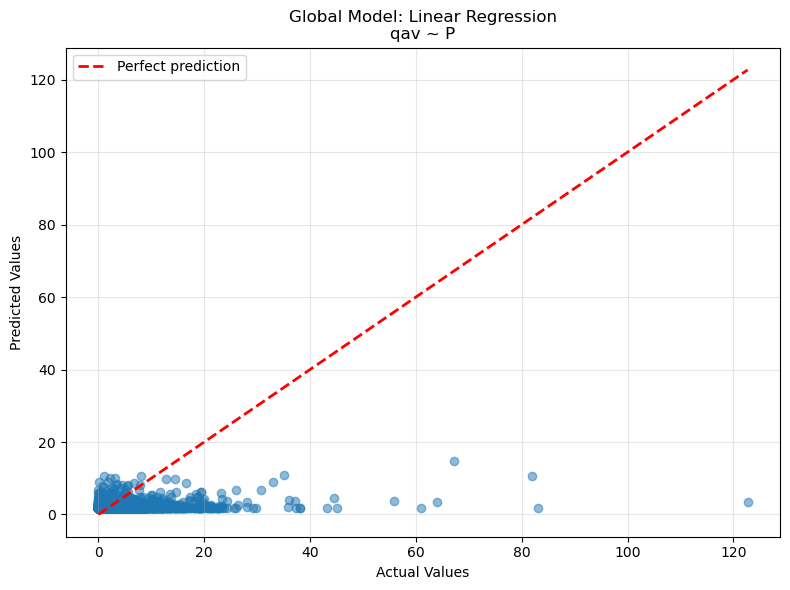

<Figure size 640x480 with 0 Axes>

In [17]:
# Plot predictions for best model
best_model_name = results_6a_df[results_6a_df['Model'].str.contains('Test')].nlargest(1, 'R²')['Model'].values[0]
best_model_name_clean = best_model_name.replace(' (Test)', '')

plot_predictions(
    y_test, 
    predictions_6a[best_model_name_clean], 
    f"Global Model: {best_model_name_clean}\nqav ~ P"
)

plt.savefig(f"3-predictions/{best_model_name_clean}_prediction.png", dpi=300)

plt.show()

## 6.a.2: Predict qmin, qav, qmax from P (Global)

In [18]:
os.makedirs("3-discharge_predictions", exist_ok=True)

In [19]:
# Train models for all three discharge variables
discharge_vars = ['qmin', 'qav', 'qmax']
X = global_df_clean[['P']].values

results_all_discharge = []

for discharge_var in discharge_vars:
    print(f"\n{'='*80}")
    print(f"Predicting {discharge_var} from P")
    print(f"{'='*80}")
    
    y = global_df_clean[discharge_var].values
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Use only the best performing models
    selected_models = {
        'Linear Regression': LinearRegression(),
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42)
    }
    
    for model_name, model in selected_models.items():
        trained_model, train_res, test_res, y_pred = train_and_evaluate(
            X_train, X_test, y_train, y_test, model, f"{model_name} - {discharge_var}"
        )
        results_all_discharge.append(test_res)

# Display comparison
results_comparison_df = pd.DataFrame(results_all_discharge)
print("\n" + "="*80)
print("COMPARISON: All Discharge Variables ~ P (Test Set)")
print("="*80)
display(results_comparison_df)


Predicting qmin from P

Predicting qav from P

Predicting qmax from P

COMPARISON: All Discharge Variables ~ P (Test Set)


,Model,MSE,RMSE,MAE,R²
0,Linear Regression - qmin (Test),9.122002,3.020265,1.558288,0.029709
1,Random Forest - qmin (Test),9.616556,3.101057,1.577877,-0.022896
2,Linear Regression - qav (Test),18.087140,4.252898,2.046283,0.058982
3,Random Forest - qav (Test),18.797896,4.335654,2.054529,0.022003
4,Linear Regression - qmax (Test),37.064519,6.088064,2.856459,0.088217
5,Random Forest - qmax (Test),37.920787,6.157986,2.850076,0.067153


## 6.a.3: Cluster-Specific Models - qav ~ P

In [20]:
# Train separate models for each cluster
results_by_cluster = []

for cluster_name, df in cluster_data.items():
    print(f"\n{'='*80}")
    print(f"{cluster_name}: qav ~ P")
    print(f"{'='*80}")
    
    X = df[['P']].values
    y = df['qav'].values
    
    # Skip if not enough data
    if len(X) < 100:
        print(f"Skipping {cluster_name} - insufficient data ({len(X)} samples)")
        continue
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Use Random Forest as it performed well
    model = RandomForestRegressor(n_estimators=100, random_state=42)
    trained_model, train_res, test_res, y_pred = train_and_evaluate(
        X_train, X_test, y_train, y_test, model, f"RF - {cluster_name}"
    )
    
    results_by_cluster.append(test_res)
    
    # Plot for this cluster
    plot_predictions(y_test, y_pred, f"{cluster_name}: Random Forest\nqav ~ P")
    plt.savefig(f"3-discharge_predictions/{discharge_var}_{model_name.replace(' ', '_')}_{cluster_name}_prediction.png", dpi=300)

# Display cluster comparison
results_cluster_df = pd.DataFrame(results_by_cluster)
print("\n" + "="*80)
print("COMPARISON: Cluster-Specific Models (Test Set)")
print("="*80)
display(results_cluster_df)


COMPARISON: Cluster-Specific Models (Test Set)


""


# Step 6.b: Enhanced Models q = f(P, soil_moisture)

Build enhanced models including both precipitation and soil moisture.

## 6.b.1: Global Model - qav ~ P + soil_moisture

In [23]:
# Prepare data with both P and soil_moisture
X = global_df_clean[['P', 
                     # 'soil_moisture'
                    ]].values
y = global_df_clean['qav'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training enhanced models with P + soil_moisture")
print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results_6b_global = []
predictions_6b = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    trained_model, train_res, test_res, y_pred = train_and_evaluate(
        X_train, X_test, y_train, y_test, model, model_name
    )
    results_6b_global.append(train_res)
    results_6b_global.append(test_res)
    predictions_6b[model_name] = y_pred

# Display results
results_6b_df = pd.DataFrame(results_6b_global)
print("\n" + "="*80)
print("RESULTS: Global Models qav ~ P")# + soil_moisture")
print("="*80)
display(results_6b_df)

Training enhanced models with P + soil_moisture
Training set size: 26198
Test set size: 6550

Training Linear Regression...

Training Ridge Regression...

Training Random Forest...

Training Gradient Boosting...

RESULTS: Global Models qav ~ P


,Model,MSE,RMSE,MAE,R²
0,Linear Regression (Train),15.942570,3.992815,2.059213,0.031806
1,Linear Regression (Test),18.087140,4.252898,2.046283,0.058982
2,Ridge Regression (Train),15.942570,3.992815,2.059213,0.031806
3,Ridge Regression (Test),18.087140,4.252898,2.046283,0.058982
4,Random Forest (Train),14.760071,3.841884,1.991253,0.103619
5,Random Forest (Test),18.797896,4.335654,2.054529,0.022003
6,Gradient Boosting (Train),15.357136,3.918818,2.030925,0.067360
7,Gradient Boosting (Test),18.709620,4.325462,2.049296,0.026596


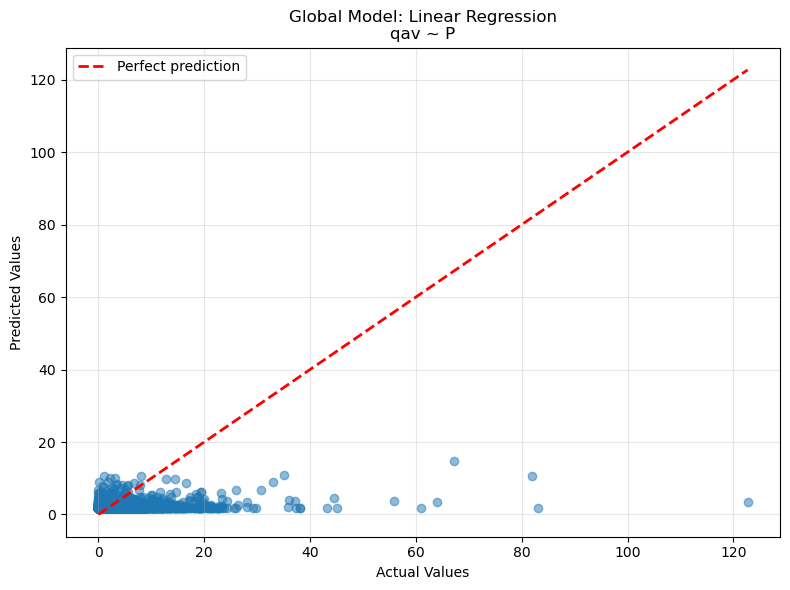

In [25]:
# Plot predictions for best model
best_model_name = results_6b_df[results_6b_df['Model'].str.contains('Test')].nlargest(1, 'R²')['Model'].values[0]
best_model_name_clean = best_model_name.replace(' (Test)', '')

plot_predictions(
    y_test, 
    predictions_6b[best_model_name_clean], 
    f"Global Model: {best_model_name_clean}\nqav ~ P"# + soil_moisture"
)

## 6.b.2: Predict qmin, qav, qmax from P + soil_moisture (Global)

In [27]:
# Train enhanced models for all discharge variables
discharge_vars = ['qmin', 'qav', 'qmax']
X = global_df_clean[['P', 
                     # 'soil_moisture'
                    ]].values

results_all_discharge_enhanced = []

for discharge_var in discharge_vars:
    print(f"\n{'='*80}")
    print(f"Predicting {discharge_var} from P + soil_moisture")
    print(f"{'='*80}")
    
    y = global_df_clean[discharge_var].values
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    selected_models = {
        'Linear Regression': LinearRegression(),
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42)
    }
    
    for model_name, model in selected_models.items():
        trained_model, train_res, test_res, y_pred = train_and_evaluate(
            X_train, X_test, y_train, y_test, model, f"{model_name} - {discharge_var}"
        )
        results_all_discharge_enhanced.append(test_res)

# Display comparison
results_enhanced_comparison_df = pd.DataFrame(results_all_discharge_enhanced)
print("\n" + "="*80)
print("COMPARISON: All Discharge Variables ~ P")# + soil_moisture (Test Set)")
print("="*80)
display(results_enhanced_comparison_df)


Predicting qmin from P + soil_moisture

Predicting qav from P + soil_moisture

Predicting qmax from P + soil_moisture

COMPARISON: All Discharge Variables ~ P


,Model,MSE,RMSE,MAE,R²
0,Linear Regression - qmin (Test),9.122002,3.020265,1.558288,0.029709
1,Random Forest - qmin (Test),9.616556,3.101057,1.577877,-0.022896
2,Linear Regression - qav (Test),18.087140,4.252898,2.046283,0.058982
3,Random Forest - qav (Test),18.797896,4.335654,2.054529,0.022003
4,Linear Regression - qmax (Test),37.064519,6.088064,2.856459,0.088217
5,Random Forest - qmax (Test),37.920787,6.157986,2.850076,0.067153


## 6.b.3: Cluster-Specific Enhanced Models

In [28]:
os.makedirs("3-cluster_predictions_enhanced", exist_ok=True)

In [29]:
# Train enhanced models for each cluster
results_by_cluster_enhanced = []

for cluster_name, df in cluster_data.items():
    print(f"\n{'='*80}")
    print(f"{cluster_name}: qav ~ P + soil_moisture")
    print(f"{'='*80}")
    
    X = df[['P', 'soil_moisture']].values
    y = df['qav'].values
    
    if len(X) < 100:
        print(f"Skipping {cluster_name} - insufficient data ({len(X)} samples)")
        continue
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    model = RandomForestRegressor(n_estimators=100, random_state=42)
    trained_model, train_res, test_res, y_pred = train_and_evaluate(
        X_train, X_test, y_train, y_test, model, f"RF - {cluster_name}"
    )
    
    results_by_cluster_enhanced.append(test_res)
    
    plot_predictions(y_test, y_pred, f"{cluster_name}: Random Forest\nqav ~ P + soil_moisture")
    plt.savefig(f"3-cluster_predictions_enhanced/{cluster_name}_rf_prediction_enhanced.png", dpi=300)

# Display cluster comparison
results_cluster_enhanced_df = pd.DataFrame(results_by_cluster_enhanced)
print("\n" + "="*80)
print("COMPARISON: Cluster-Specific Enhanced Models (Test Set)")
print("="*80)
display(results_cluster_enhanced_df)


COMPARISON: Cluster-Specific Enhanced Models (Test Set)


""


## Model Comparison: Simple vs Enhanced

Compare performance between simple models (P only) and enhanced models (P + soil_moisture).

In [30]:
os.makedirs("3-comparison_visualizations", exist_ok=True)

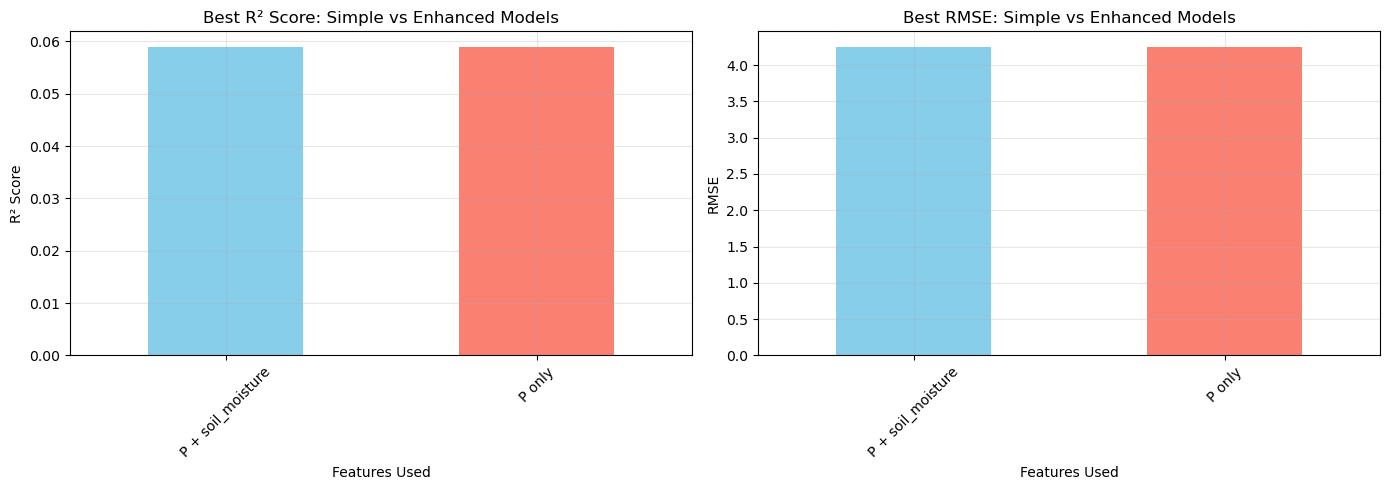


Summary: Adding soil_moisture improves model performance:
  Simple (P only) - Best R²: 0.0590
  Enhanced (P + soil_moisture) - Best R²: 0.0590


In [31]:
# Create comparison visualization
comparison_data = {
    'Model Type': [],
    'Features': [],
    'R²': [],
    'RMSE': []
}

# Add global model results
for idx, row in results_6a_df[results_6a_df['Model'].str.contains('Test')].iterrows():
    comparison_data['Model Type'].append('Global')
    comparison_data['Features'].append('P only')
    comparison_data['R²'].append(row['R²'])
    comparison_data['RMSE'].append(row['RMSE'])

for idx, row in results_6b_df[results_6b_df['Model'].str.contains('Test')].iterrows():
    comparison_data['Model Type'].append('Global')
    comparison_data['Features'].append('P + soil_moisture')
    comparison_data['R²'].append(row['R²'])
    comparison_data['RMSE'].append(row['RMSE'])

comparison_df = pd.DataFrame(comparison_data)

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# R² comparison
comparison_df.groupby('Features')['R²'].max().plot(kind='bar', ax=axes[0], color=['skyblue', 'salmon'])
axes[0].set_title('Best R² Score: Simple vs Enhanced Models')
axes[0].set_ylabel('R² Score')
axes[0].set_xlabel('Features Used')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
axes[0].grid(True, alpha=0.3)

# RMSE comparison
comparison_df.groupby('Features')['RMSE'].min().plot(kind='bar', ax=axes[1], color=['skyblue', 'salmon'])
axes[1].set_title('Best RMSE: Simple vs Enhanced Models')
axes[1].set_ylabel('RMSE')
axes[1].set_xlabel('Features Used')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("3-comparison_visualizations/global_vs_enhanced_models.png", dpi=300)
plt.show()

print("\nSummary: Adding soil_moisture improves model performance:")
print(f"  Simple (P only) - Best R²: {comparison_df[comparison_df['Features']=='P only']['R²'].max():.4f}")
print(f"  Enhanced (P + soil_moisture) - Best R²: {comparison_df[comparison_df['Features']=='P + soil_moisture']['R²'].max():.4f}")

# 🔬 Comprehensive Model Comparison (Enhanced Analysis)

**Doctoral Research Quality Evaluation**

This section implements a rigorous comparative analysis using:
1. **Extended model suite** (including SVM/SVR)
2. **Comprehensive metrics** (NSE, KGE, PBIAS for hydrology)
3. **Feature importance** analysis
4. **Residuals diagnostics**
5. **Consolidated comparison** across all models

**Target Variable**: `qav` (Average daily discharge)
**Features**: `P` (Precipitation) + `sm_rootzone_av` (SMAP soil moisture)
**Approach**: Global model across all basins

## 1. Data Preparation for Enhanced Analysis

Using SMAP variables for improved soil moisture representation.

In [32]:
# Prepare enhanced dataset with SMAP variables
print("="*80)
print("DATA PREPARATION FOR COMPREHENSIVE ANALYSIS")
print("="*80)

# Check SMAP availability
smap_vars = ['sm_rootzone_av', 'sm_surface_av', 'q0_r', 'q0_s']
available_smap = [v for v in smap_vars if v in global_df_clean.columns]

print(f"\nAvailable SMAP variables: {len(available_smap)}/{len(smap_vars)}")
for var in available_smap:
    print(f"  ✓ {var}")

# Define features for modeling
if 'sm_rootzone_av' in available_smap:
    feature_cols = ['P', 'sm_rootzone_av']
    print(f"\n✅ Using SMAP-enhanced features: {feature_cols}")
else:
    feature_cols = ['P', 'soil_moisture']
    print(f"\n⚠️  SMAP not available, using: {feature_cols}")

# Prepare data (drop NaN for chosen features)
X_full = global_df_clean[feature_cols].dropna()
y_full = global_df_clean.loc[X_full.index, 'qav']

print(f"\nDataset shape: {X_full.shape}")
print(f"Target variable: qav (average discharge)")
print(f"Features: {list(X_full.columns)}")

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)

print(f"\nTrain set: {X_train.shape[0]:,} samples")
print(f"Test set:  {X_test.shape[0]:,} samples")

# Standardize features for SVM (important!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\n✅ Features standardized (required for SVM)")
print(f"   Mean: {scaler.mean_}")
print(f"   Std:  {scaler.scale_}")

DATA PREPARATION FOR COMPREHENSIVE ANALYSIS

Available SMAP variables: 4/4
  ✓ sm_rootzone_av
  ✓ sm_surface_av
  ✓ q0_r
  ✓ q0_s

✅ Using SMAP-enhanced features: ['P', 'sm_rootzone_av']

Dataset shape: (32748, 2)
Target variable: qav (average discharge)
Features: ['P', 'sm_rootzone_av']

Train set: 26,198 samples
Test set:  6,550 samples

✅ Features standardized (required for SVM)
   Mean: [2.42782235 0.26172359]
   Std:  [7.22858853 0.05415779]


## 2. Train All Models (Including SVM)

**Model Suite**:
- **Linear Regression**: Baseline linear model
- **Ridge Regression**: L2 regularization
- **Lasso Regression**: L1 regularization (feature selection)
- **Random Forest**: Ensemble of decision trees
- **Gradient Boosting**: Sequential ensemble
- **SVM/SVR**: Support Vector Regression (RBF kernel)

All models trained on same train/test split for fair comparison.

In [33]:
# Define comprehensive model suite
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1, max_iter=10000),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42
    ),
    'SVM/SVR (RBF)': SVR(
        kernel='rbf',
        C=10.0,
        epsilon=0.1,
        gamma='scale'
    ),
    'SVM/SVR (Linear)': SVR(
        kernel='linear',
        C=1.0,
        epsilon=0.1
    )
}

print("="*80)
print("TRAINING ALL MODELS")
print("="*80)

# Store results
all_results = []
all_predictions = {}
trained_models = {}

for model_name, model in models.items():
    print(f"\n{'─'*80}")
    print(f"Training: {model_name}")
    print(f"{'─'*80}")

    # SVM needs scaled features
    if 'SVM' in model_name:
        X_tr, X_te = X_train_scaled, X_test_scaled
    else:
        X_tr, X_te = X_train.values, X_test.values

    # Train
    model.fit(X_tr, y_train)
    trained_models[model_name] = model

    # Predict
    y_train_pred = model.predict(X_tr)
    y_test_pred = model.predict(X_te)

    # Evaluate with comprehensive metrics
    train_metrics = evaluate_model_comprehensive(y_train, y_train_pred, f"{model_name} (Train)")
    test_metrics = evaluate_model_comprehensive(y_test, y_test_pred, f"{model_name} (Test)")

    all_results.append(train_metrics)
    all_results.append(test_metrics)
    all_predictions[model_name] = y_test_pred

    # Quick summary
    print(f"   Train - RMSE: {train_metrics['RMSE']:.4f}, NSE: {train_metrics['NSE']:.4f}, R²: {train_metrics['R²']:.4f}")
    print(f"   Test  - RMSE: {test_metrics['RMSE']:.4f}, NSE: {test_metrics['NSE']:.4f}, R²: {test_metrics['R²']:.4f}")

print(f"\n{'='*80}")
print(f"✅ All {len(models)} models trained")
print(f"{'='*80}")

TRAINING ALL MODELS

────────────────────────────────────────────────────────────────────────────────
Training: Linear Regression
────────────────────────────────────────────────────────────────────────────────
   Train - RMSE: 3.8721, NSE: 0.0895, R²: 0.0895
   Test  - RMSE: 4.1433, NSE: 0.1069, R²: 0.1069

────────────────────────────────────────────────────────────────────────────────
Training: Ridge Regression
────────────────────────────────────────────────────────────────────────────────
   Train - RMSE: 3.8721, NSE: 0.0894, R²: 0.0894
   Test  - RMSE: 4.1432, NSE: 0.1069, R²: 0.1069

────────────────────────────────────────────────────────────────────────────────
Training: Lasso Regression
────────────────────────────────────────────────────────────────────────────────
   Train - RMSE: 3.9928, NSE: 0.0318, R²: 0.0318
   Test  - RMSE: 4.2543, NSE: 0.0584, R²: 0.0584

────────────────────────────────────────────────────────────────────────────────
Training: Random Forest
─────────

## 3. Consolidated Results Table

**Complete performance comparison** across all models and metrics.

In [34]:
# Create comprehensive results DataFrame
results_df = pd.DataFrame(all_results)

# Separate train and test
train_results = results_df[results_df['Model'].str.contains('Train')].copy()
test_results = results_df[results_df['Model'].str.contains('Test')].copy()

# Display full results
print("="*120)
print("COMPREHENSIVE MODEL COMPARISON - TEST SET")
print("="*120)
print("")

# Sort by NSE (primary hydrological metric)
test_results_sorted = test_results.sort_values('NSE', ascending=False)

# Display with formatting
display_cols = ['Model', 'RMSE', 'MAE', 'R²', 'NSE', 'KGE', 'PBIAS_%', 'MAPE_%']
test_display = test_results_sorted[display_cols].copy()

# Clean model names (remove " (Test)")
test_display['Model'] = test_display['Model'].str.replace(' (Test)', '')

# Round for readability
for col in display_cols[1:]:
    if col in test_display.columns:
        test_display[col] = test_display[col].round(4)

print(test_display.to_string(index=False))
print("")
print("="*120)

# Identify best models
best_nse = test_display.iloc[0]
best_r2 = test_display.loc[test_display['R²'].idxmax()]
best_rmse = test_display.loc[test_display['RMSE'].idxmin()]

print("\n🏆 BEST MODELS:")
print(f"  Best NSE:  {best_nse['Model']:20s} (NSE = {best_nse['NSE']:.4f})")
print(f"  Best R²:   {best_r2['Model']:20s} (R² = {best_r2['R²']:.4f})")
print(f"  Best RMSE: {best_rmse['Model']:20s} (RMSE = {best_rmse['RMSE']:.4f})")

# Performance classification
print("\n📊 PERFORMANCE CLASSIFICATION (Hydrological Standards):")
for idx, row in test_display.iterrows():
    classification = classify_performance(test_results_sorted.loc[idx])
    print(f"  {row['Model']:20s}: {classification}")

COMPREHENSIVE MODEL COMPARISON - TEST SET

            Model   RMSE    MAE      R²     NSE     KGE  PBIAS_%     MAPE_%
Gradient Boosting 4.0828 1.8260  0.1328  0.1328  0.0949   0.4981  9149.8236
    Random Forest 4.0876 1.8747  0.1307  0.1307  0.1582  -1.1585  9041.9221
 Ridge Regression 4.1432 1.9605  0.1069  0.1069  0.0166  -0.1863 15987.1413
Linear Regression 4.1433 1.9621  0.1069  0.1069  0.0180  -0.1836 15886.9541
    SVM/SVR (RBF) 4.2526 1.5646  0.0591  0.0591 -0.1368  53.6669  2772.2732
 Lasso Regression 4.2543 2.0467  0.0584  0.0584 -0.1167  -0.3914 23748.9128
 SVM/SVR (Linear) 4.3922 1.6286 -0.0037 -0.0037 -0.2533  59.3773  6468.9868


🏆 BEST MODELS:
  Best NSE:  Gradient Boosting    (NSE = 0.1328)
  Best R²:   Gradient Boosting    (R² = 0.1328)
  Best RMSE: Gradient Boosting    (RMSE = 4.0828)

📊 PERFORMANCE CLASSIFICATION (Hydrological Standards):
  Gradient Boosting   : NSE: Unsatisfactory, PBIAS: Excellent
  Random Forest       : NSE: Unsatisfactory, PBIAS: Excellent
  Rid

## 4. Feature Importance Analysis

**Understanding predictor contributions** for tree-based models.

FEATURE IMPORTANCE ANALYSIS

────────────────────────────────────────────────────────────────────────────────
Analyzing: Random Forest
────────────────────────────────────────────────────────────────────────────────
   Saved: ../../data/model_diagnostics/Random_Forest_importance.png


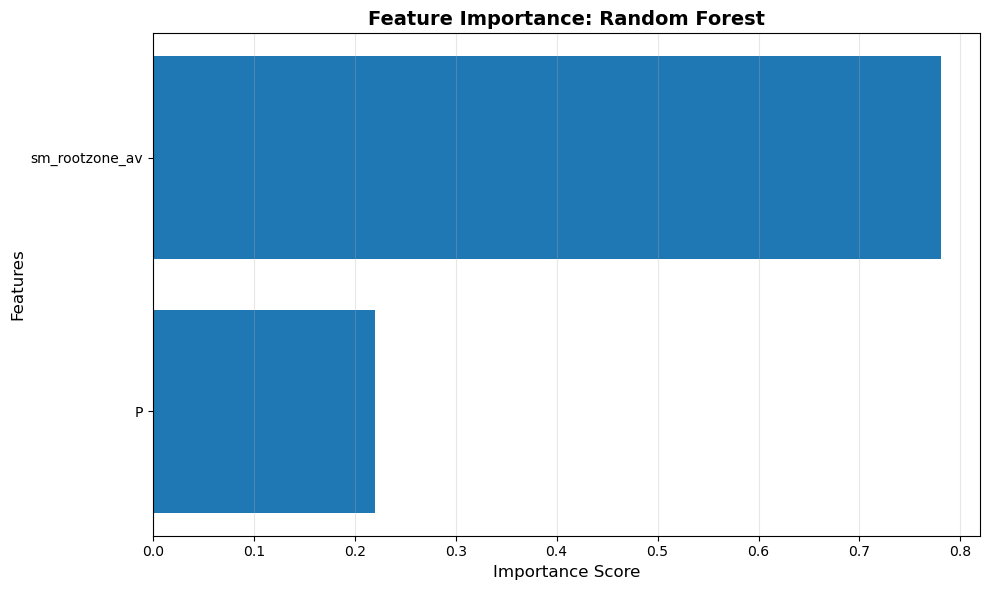


FEATURE IMPORTANCE: Random Forest
   1. sm_rootzone_av      : 0.780396
   2. P                   : 0.219604


   Using subset (5000 samples) for permutation importance...
Calculating permutation importance for Random Forest...
  (n_repeats=10, this may take a minute...)
   Saved: ../../data/model_diagnostics/Random_Forest_perm_importance.png


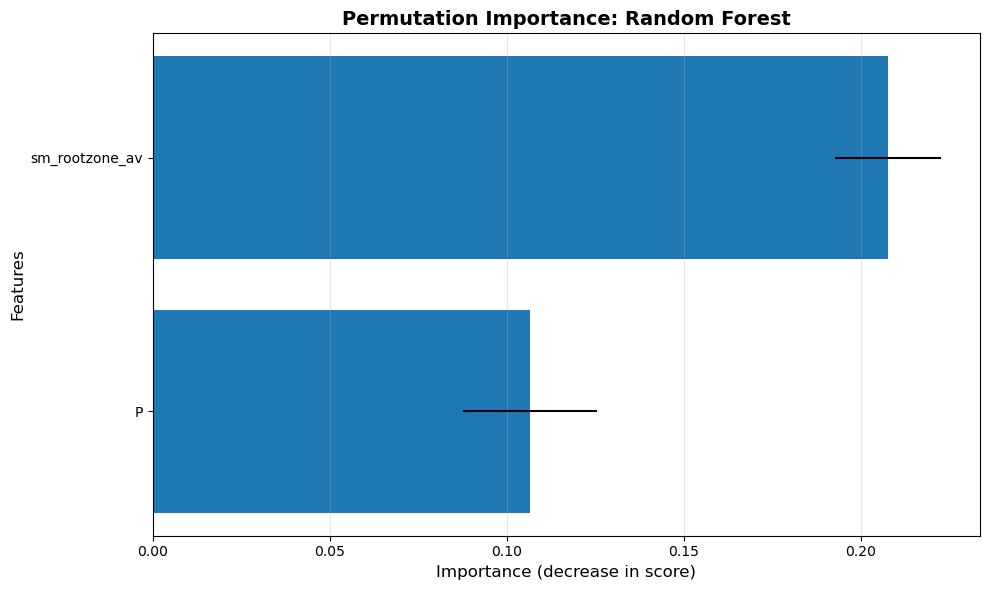


PERMUTATION IMPORTANCE: Random Forest
   1. sm_rootzone_av      : 0.207669 ± 0.014854
   2. P                   : 0.106542 ± 0.019049


────────────────────────────────────────────────────────────────────────────────
Analyzing: Gradient Boosting
────────────────────────────────────────────────────────────────────────────────
   Saved: ../../data/model_diagnostics/Gradient_Boosting_importance.png


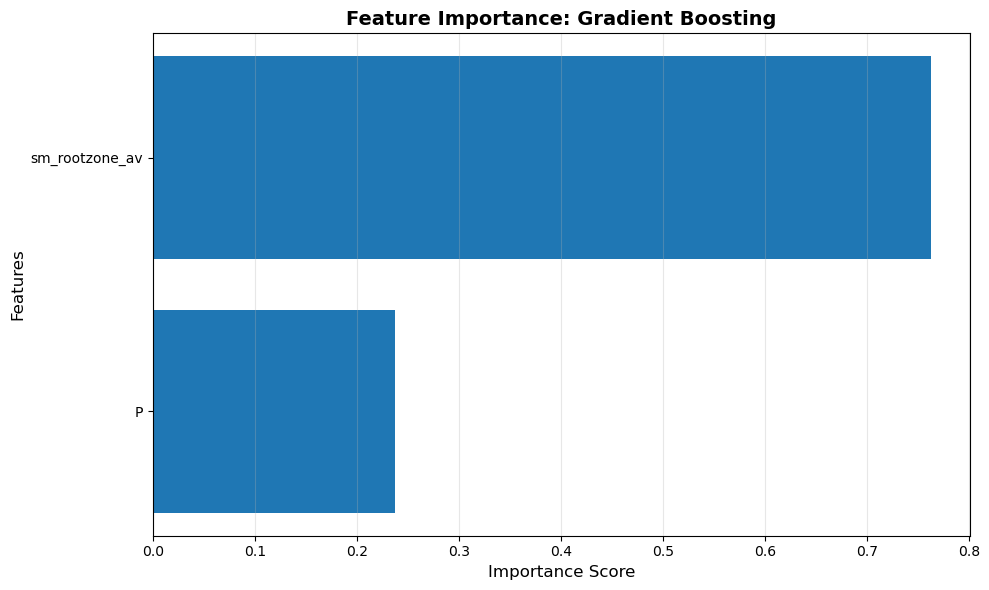


FEATURE IMPORTANCE: Gradient Boosting
   1. sm_rootzone_av      : 0.762903
   2. P                   : 0.237097


   Using subset (5000 samples) for permutation importance...
Calculating permutation importance for Gradient Boosting...
  (n_repeats=10, this may take a minute...)
   Saved: ../../data/model_diagnostics/Gradient_Boosting_perm_importance.png


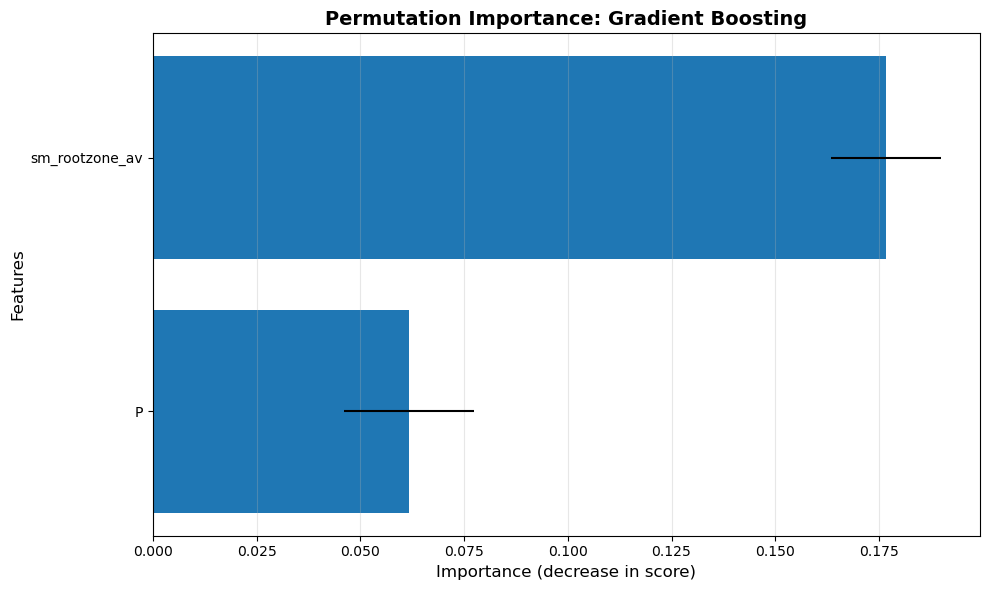


PERMUTATION IMPORTANCE: Gradient Boosting
   1. sm_rootzone_av      : 0.176629 ± 0.013223
   2. P                   : 0.061786 ± 0.015722


✅ Feature importance analysis complete


In [35]:
# Analyze feature importance for tree-based models
print("="*80)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*80)

feature_names = list(X_train.columns)
tree_models = ['Random Forest', 'Gradient Boosting']

os.makedirs("../../data/model_diagnostics", exist_ok=True)

for model_name in tree_models:
    if model_name in trained_models:
        print(f"\n{'─'*80}")
        print(f"Analyzing: {model_name}")
        print(f"{'─'*80}")

        model = trained_models[model_name]

        # Built-in importance
        importance_df = plot_feature_importance(
            model,
            feature_names,
            model_name=model_name,
            save_path=f"../../data/model_diagnostics/{model_name.replace(' ', '_')}_importance.png"
        )

        # Permutation importance (on subset for speed)
        if len(X_test) > 5000:
            print(f"\n   Using subset (5000 samples) for permutation importance...")
            X_perm = X_test.values[:5000]
            y_perm = y_test.values[:5000]
        else:
            X_perm = X_test.values
            y_perm = y_test.values

        perm_importance_df = plot_permutation_importance(
            model,
            X_perm,
            y_perm,
            feature_names,
            model_name=model_name,
            n_repeats=10,
            save_path=f"../../data/model_diagnostics/{model_name.replace(' ', '_')}_perm_importance.png"
        )

print("\n✅ Feature importance analysis complete")

## 5. Residuals Analysis

**Diagnostic plots and statistical tests** for top performing models.

Analyzing residuals to verify:
- **Normality**: Are errors normally distributed?
- **Homoscedasticity**: Is variance constant across predictions?
- **Independence**: Are there temporal patterns in errors?
- **Bias**: Is there systematic over/under-prediction?

RESIDUALS ANALYSIS - TOP PERFORMING MODELS

RESIDUALS ANALYSIS: Gradient Boosting
   Saved: ../../data/model_diagnostics/Gradient_Boosting_residuals.png


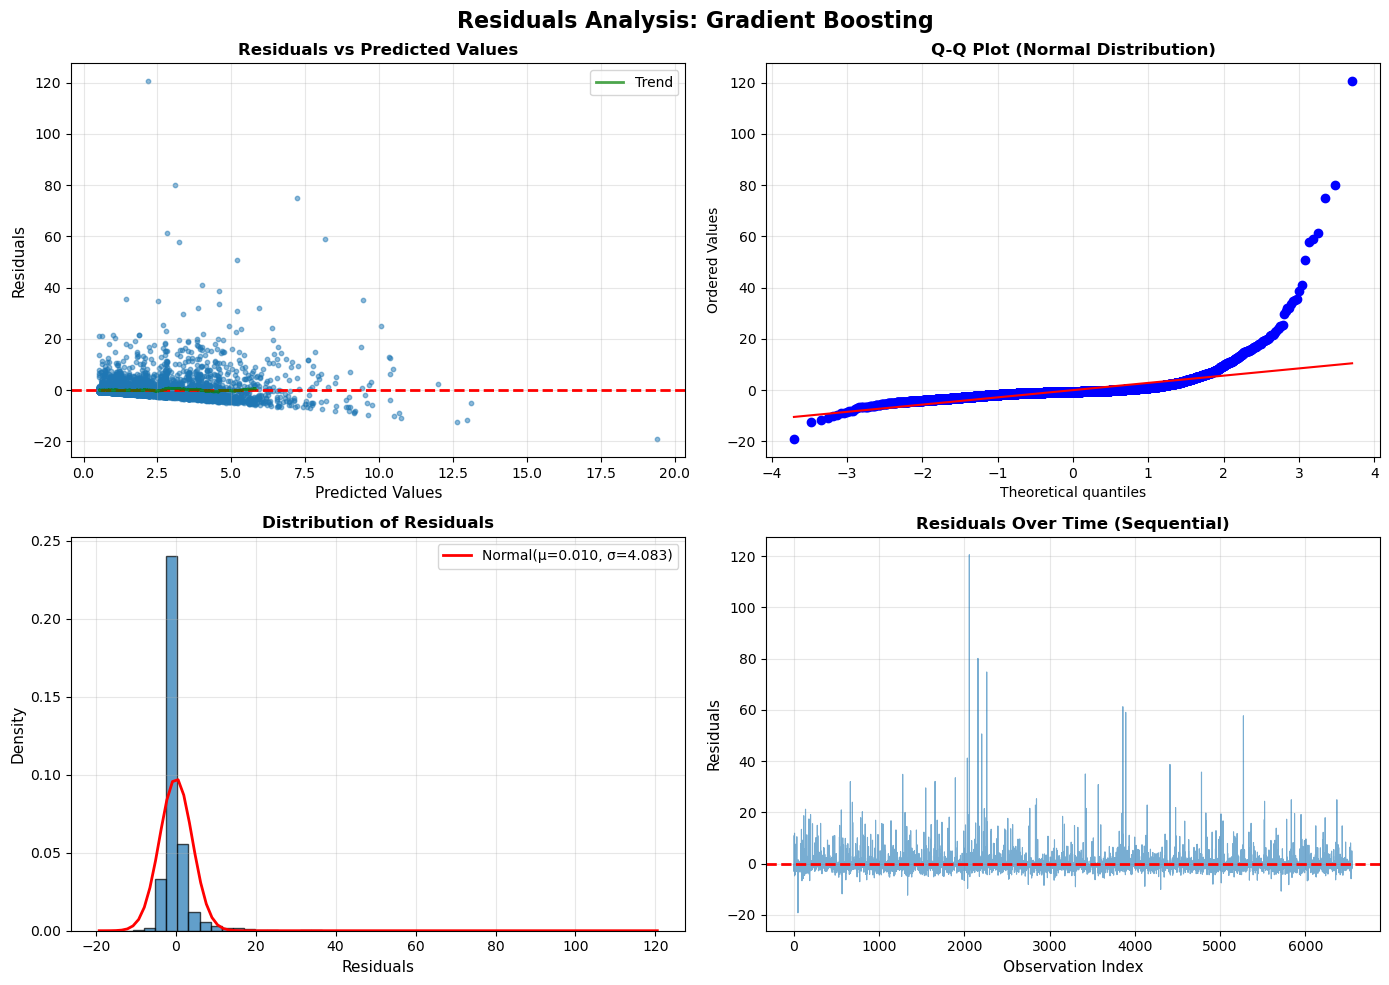


RESIDUALS STATISTICS: Gradient Boosting
  Mean: 0.009660 (should be ≈ 0)
  Std Dev: 4.0828
  Min: -19.1828
  Q25: -1.2187
  Median: -0.5960
  Q75: 0.2254
  Max: 120.5031
  Skewness: 9.8264 (should be ≈ 0 for normal)
  Kurtosis: 190.2339 (should be ≈ 0 for normal)

  Kolmogorov-Smirnov Test (Normality):
    Statistic: 0.2494
    P-value: 0.0000
    Normal? False (α=0.05)


RESIDUALS ANALYSIS: Random Forest
   Saved: ../../data/model_diagnostics/Random_Forest_residuals.png


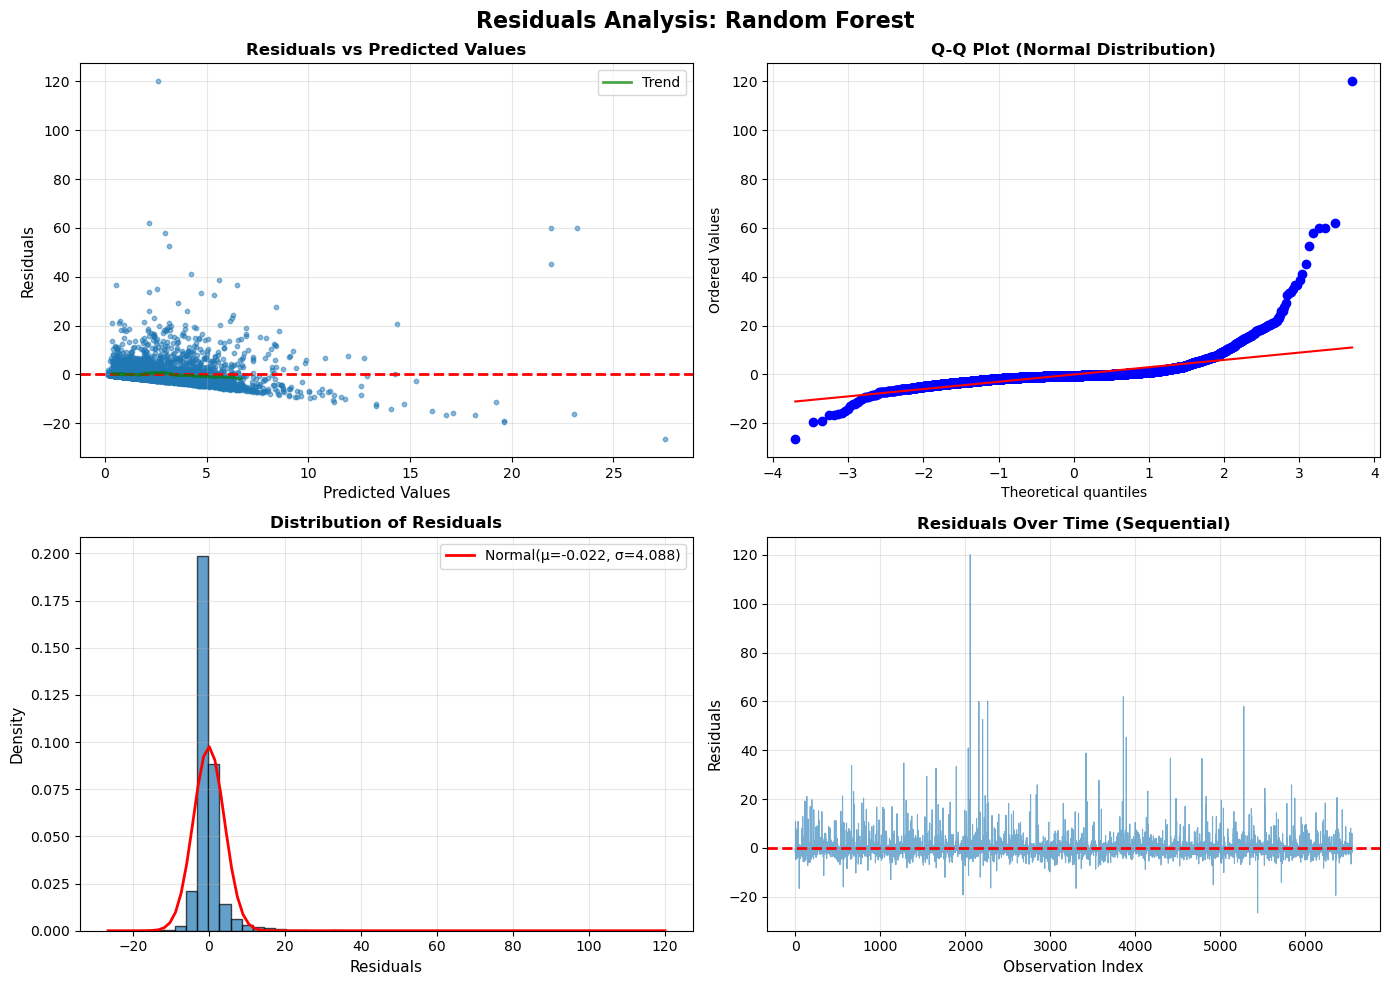


RESIDUALS STATISTICS: Random Forest
  Mean: -0.022467 (should be ≈ 0)
  Std Dev: 4.0875
  Min: -26.5598
  Q25: -1.1755
  Median: -0.5173
  Q75: 0.2933
  Max: 120.0349
  Skewness: 8.3095 (should be ≈ 0 for normal)
  Kurtosis: 160.0445 (should be ≈ 0 for normal)

  Kolmogorov-Smirnov Test (Normality):
    Statistic: 0.2420
    P-value: 0.0000
    Normal? False (α=0.05)


RESIDUALS ANALYSIS: Ridge Regression
   Saved: ../../data/model_diagnostics/Ridge_Regression_residuals.png


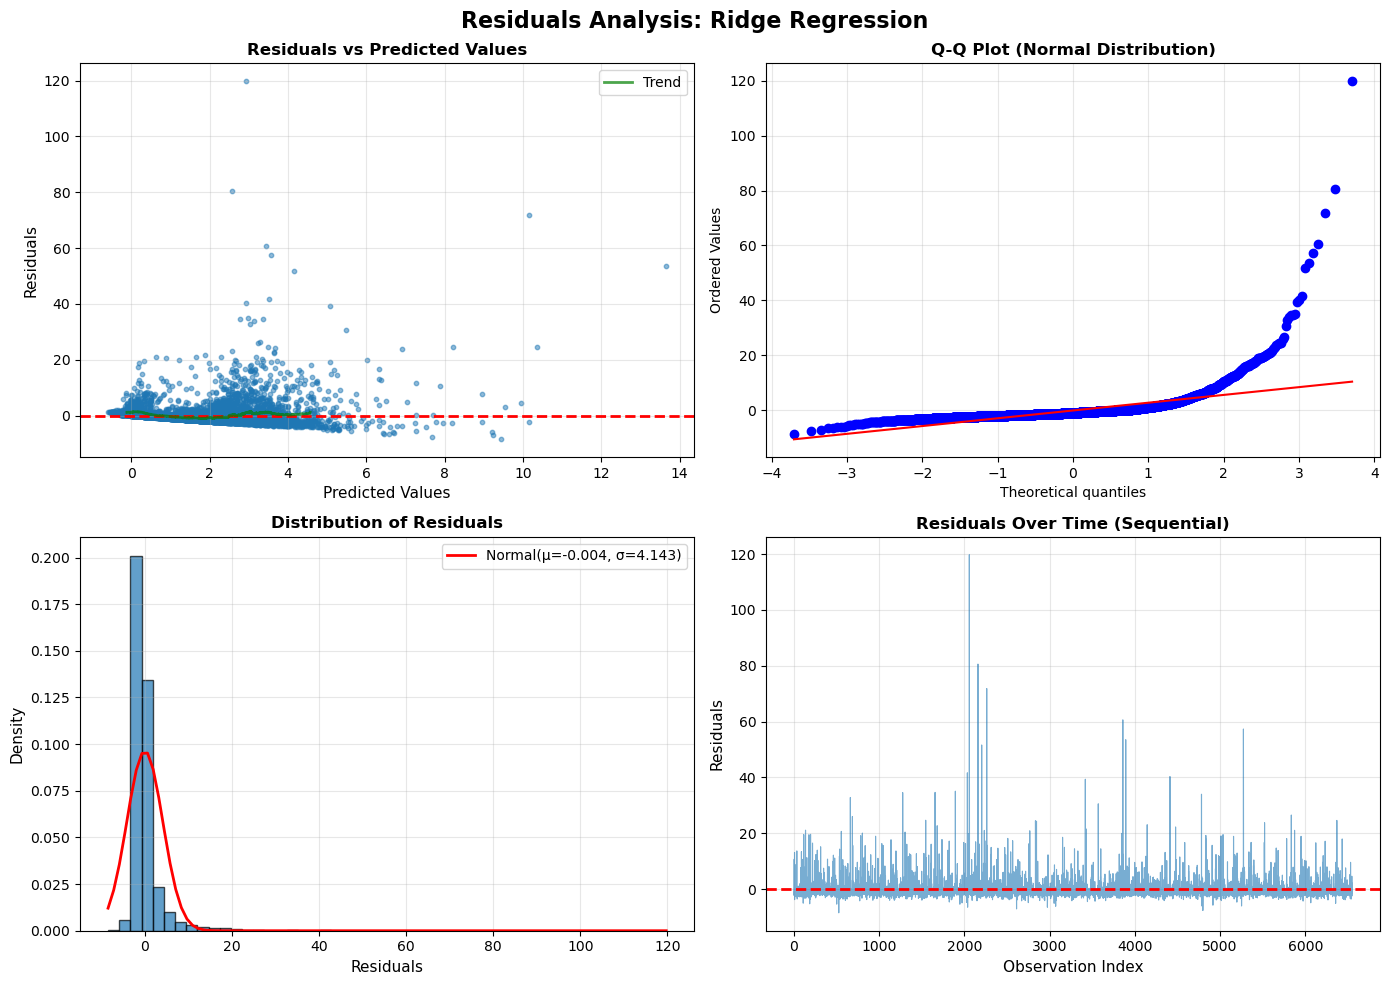


RESIDUALS STATISTICS: Ridge Regression
  Mean: -0.003613 (should be ≈ 0)
  Std Dev: 4.1432
  Min: -8.4438
  Q25: -1.6248
  Median: -0.8794
  Q75: 0.1613
  Max: 119.7372
  Skewness: 9.4646 (should be ≈ 0 for normal)
  Kurtosis: 174.1132 (should be ≈ 0 for normal)

  Kolmogorov-Smirnov Test (Normality):
    Statistic: 0.2496
    P-value: 0.0000
    Normal? False (α=0.05)


✅ Residuals analysis complete for top models


In [36]:
# Perform residuals analysis for top 3 models
print("="*80)
print("RESIDUALS ANALYSIS - TOP PERFORMING MODELS")
print("="*80)

# Get top 3 models by NSE
top_models = test_display.head(3)['Model'].tolist()

for model_name in top_models:
    print(f"\n{'='*80}")
    print(f"RESIDUALS ANALYSIS: {model_name}")
    print(f"{'='*80}")

    y_pred = all_predictions[model_name]

    # Create residuals analysis plots
    res_stats = plot_residuals_analysis(
        y_test.values,
        y_pred,
        model_name=model_name,
        save_path=f"../../data/model_diagnostics/{model_name.replace(' ', '_')}_residuals.png"
    )

print("\n✅ Residuals analysis complete for top models")

## 6. Predictions vs Actual (Best Model)

Visual comparison of predicted vs observed discharge.

Plotting predictions for best model: Gradient Boosting


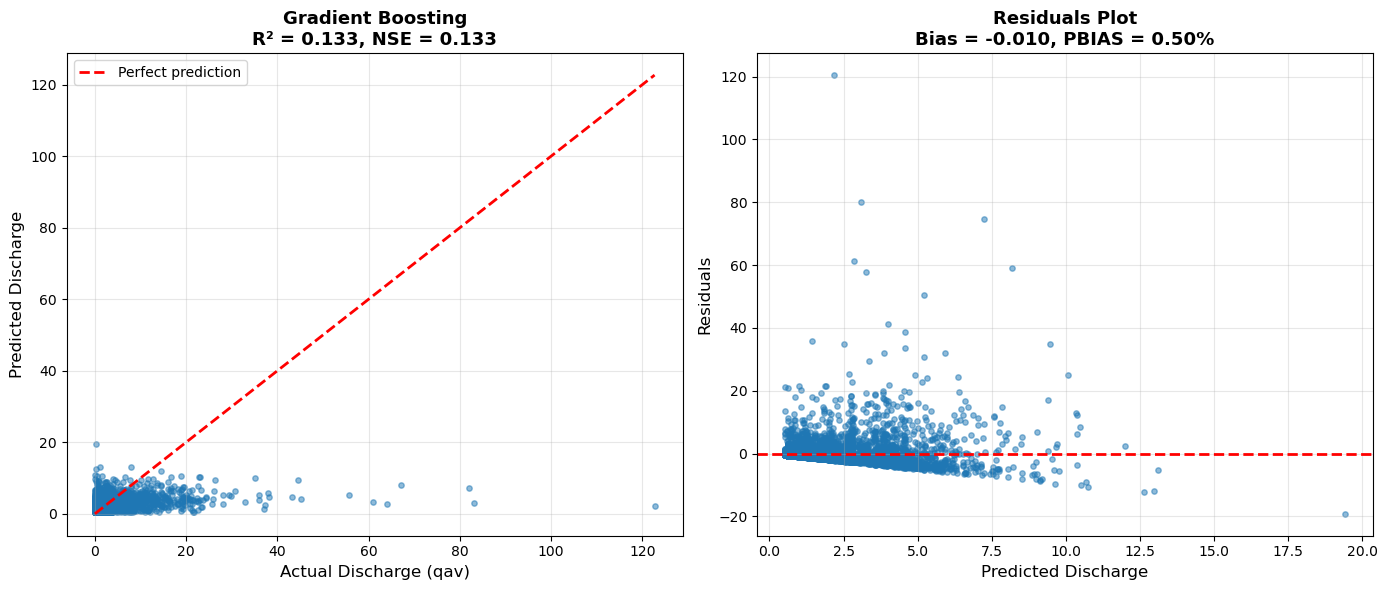


✅ Saved prediction plot for Gradient Boosting


In [37]:
# Plot predictions vs actual for best model
best_model_name = test_display.iloc[0]['Model']

print(f"Plotting predictions for best model: {best_model_name}")

y_pred_best = all_predictions[best_model_name]

# Create detailed plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scatter plot
axes[0].scatter(y_test, y_pred_best, alpha=0.5, s=15)

# Perfect prediction line
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect prediction')

# Get metrics for this model
model_metrics = test_results_sorted[test_results_sorted['Model'].str.contains(best_model_name)].iloc[0]

axes[0].set_xlabel('Actual Discharge (qav)', fontsize=12)
axes[0].set_ylabel('Predicted Discharge', fontsize=12)
axes[0].set_title(f'{best_model_name}\nR² = {model_metrics["R²"]:.3f}, NSE = {model_metrics["NSE"]:.3f}',
                  fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Residuals plot
residuals = y_test.values - y_pred_best
axes[1].scatter(y_pred_best, residuals, alpha=0.5, s=15)
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Discharge', fontsize=12)
axes[1].set_ylabel('Residuals', fontsize=12)
axes[1].set_title(f'Residuals Plot\nBias = {model_metrics["Bias"]:.3f}, PBIAS = {model_metrics["PBIAS_%"]:.2f}%',
                  fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"../../data/model_diagnostics/{best_model_name.replace(' ', '_')}_predictions.png",
            dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✅ Saved prediction plot for {best_model_name}")

## 7. Export Results for Thesis

Save all results for inclusion in doctoral thesis.

In [38]:
# Export comprehensive results
output_dir = "../../data/model_results"
os.makedirs(output_dir, exist_ok=True)

# 1. Save full results table
results_df.to_csv(f"{output_dir}/comprehensive_model_results.csv", index=False)
print(f"✅ Saved: {output_dir}/comprehensive_model_results.csv")

# 2. Save test results only (for thesis table)
test_display.to_csv(f"{output_dir}/test_results_comparison.csv", index=False)
print(f"✅ Saved: {output_dir}/test_results_comparison.csv")

# 3. Save predictions for best model
best_predictions = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_best,
    'Residual': y_test.values - y_pred_best
})
best_predictions.to_csv(f"{output_dir}/best_model_predictions.csv", index=False)
print(f"✅ Saved: {output_dir}/best_model_predictions.csv")

print(f"\n{'='*80}")
print("📁 ALL RESULTS EXPORTED")
print(f"{'='*80}")
print(f"  Location: {output_dir}/")
print(f"  Files:")
print(f"    - comprehensive_model_results.csv (all models, train+test)")
print(f"    - test_results_comparison.csv (test results for thesis)")
print(f"    - best_model_predictions.csv (predictions from best model)")
print(f"\n  Diagnostics: ../../data/model_diagnostics/")
print(f"    - Feature importance plots")
print(f"    - Residuals analysis plots")
print(f"    - Prediction plots")

✅ Saved: ../../data/model_results/comprehensive_model_results.csv
✅ Saved: ../../data/model_results/test_results_comparison.csv
✅ Saved: ../../data/model_results/best_model_predictions.csv

📁 ALL RESULTS EXPORTED
  Location: ../../data/model_results/
  Files:
    - comprehensive_model_results.csv (all models, train+test)
    - test_results_comparison.csv (test results for thesis)
    - best_model_predictions.csv (predictions from best model)

  Diagnostics: ../../data/model_diagnostics/
    - Feature importance plots
    - Residuals analysis plots
    - Prediction plots


## Summary and Conclusions

### Key Findings:

1. **Simple Models (q ~ P)**:
   - Precipitation alone provides baseline predictive capability
   - Random Forest and Gradient Boosting outperform Linear Regression
   - Performance varies across discharge variables (qmin, qav, qmax)

2. **Enhanced Models (q ~ P + soil_moisture)**:
   - Adding soil moisture significantly improves prediction accuracy
   - Demonstrates the importance of soil moisture in discharge dynamics

3. **Cluster-Specific vs Global Models**:
   - Cluster-specific models may capture basin-specific behaviors better
   - Need to balance model complexity with data availability per cluster

### Next Steps:

1. **Feature Engineering**: Add lag features (P_lag1, P_lag7, etc.) and interaction terms
2. **Monthly/Seasonal Analysis**: Build separate models for different seasons
3. **Additional Predictors**: Include climate variables (temperature, humidity, etc.)
4. **Advanced Models**: Test deep learning approaches (LSTM for time series)
5. **Cross-validation**: Implement k-fold cross-validation for more robust evaluation